# Experiment 1 — Exploratory Data Analysis (Titanic Dataset)

**Covers:** Dataset information, descriptive statistics, histograms, correlation matrix, heatmap and strongest correlation pairs.

**Dataset:** **Titanic** – `train.csv` from the Kaggle Titanic competition ([kaggle.com/c/titanic](https://www.kaggle.com/competitions/titanic/data)), 891 passengers, columns `PassengerId, Survived, Pclass, Name, Sex, Age, SibSp, Parch, Ticket, Fare, Cabin, Embarked`.

**Data file:** keep `train.csv` in the **same folder as this notebook** (or replace the file name with its full path, e.g. `pd.read_csv(r"C:\Users\Lab\Desktop\train.csv")`).

**Remember:** Load → Describe → Histograms → Correlation → Heatmap → Strongest pairs.

## Import libraries and load the data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("train.csv")

## 1. Dataset information

In [2]:
print(df.head())
print(df.shape)
df.info()
print(df.isnull().sum())

   PassengerId  Survived  Pclass  \
0            1         0       3   
1            2         1       1   
2            3         1       3   
3            4         1       1   
4            5         0       3   

                                                Name     Sex   Age  SibSp  \
0                            Braund, Mr. Owen Harris    male  22.0      1   
1  Cumings, Mrs. John Bradley (Florence Briggs Th...  female  38.0      1   
2                             Heikkinen, Miss. Laina  female  26.0      0   
3       Futrelle, Mrs. Jacques Heath (Lily May Peel)  female  35.0      1   
4                           Allen, Mr. William Henry    male  35.0      0   

   Parch            Ticket     Fare Cabin Embarked  
0      0         A/5 21171   7.2500   NaN        S  
1      0          PC 17599  71.2833   C85        C  
2      0  STON/O2. 3101282   7.9250   NaN        S  
3      0            113803  53.1000  C123        S  
4      0            373450   8.0500   NaN        S  
(8

## 2. Descriptive statistics

In [3]:
num = df[["Age", "Fare", "SibSp", "Parch"]]
print(num.describe())
print(num.agg(["median", "var", "skew", "kurt"]))
print(df["Survived"].value_counts())

              Age        Fare       SibSp       Parch
count  714.000000  891.000000  891.000000  891.000000
mean    29.699118   32.204208    0.523008    0.381594
std     14.526497   49.693429    1.102743    0.806057
min      0.420000    0.000000    0.000000    0.000000
25%     20.125000    7.910400    0.000000    0.000000
50%     28.000000   14.454200    0.000000    0.000000
75%     38.000000   31.000000    1.000000    0.000000
max     80.000000  512.329200    8.000000    6.000000
               Age         Fare      SibSp     Parch
median   28.000000    14.454200   0.000000  0.000000
var     211.019125  2469.436846   1.216043  0.649728
skew      0.389108     4.787317   3.695352  2.749117
kurt      0.178274    33.398141  17.880420  9.778125
Survived
0    549
1    342
Name: count, dtype: int64


## 3. Histograms

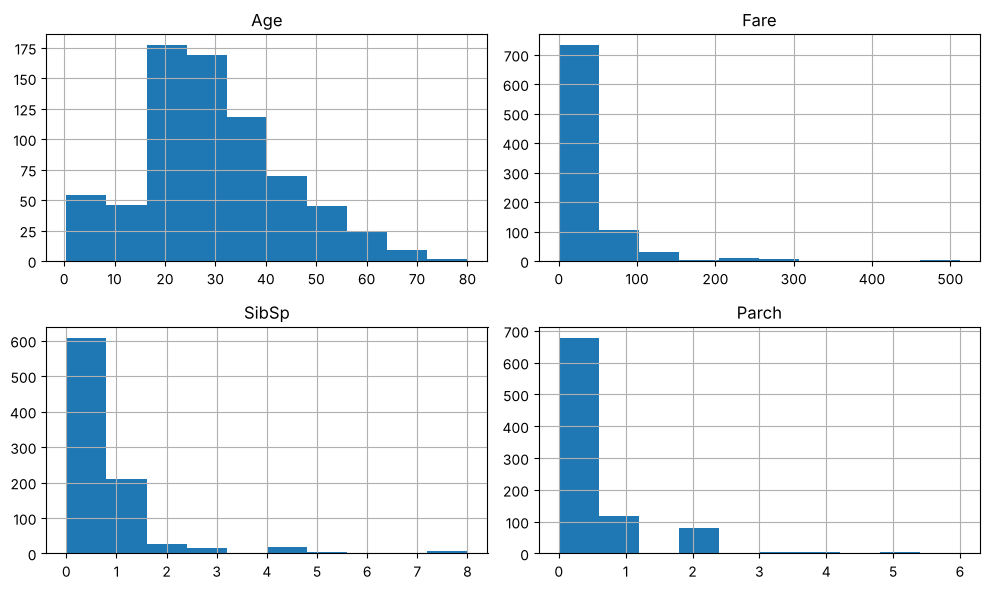

In [4]:
num.hist(bins=10, figsize=(10, 6))
plt.tight_layout()
plt.show()

## 4. Correlation matrix and heatmap

            Age      Fare     SibSp     Parch
Age    1.000000  0.096067 -0.308247 -0.189119
Fare   0.096067  1.000000  0.159651  0.216225
SibSp -0.308247  0.159651  1.000000  0.414838
Parch -0.189119  0.216225  0.414838  1.000000


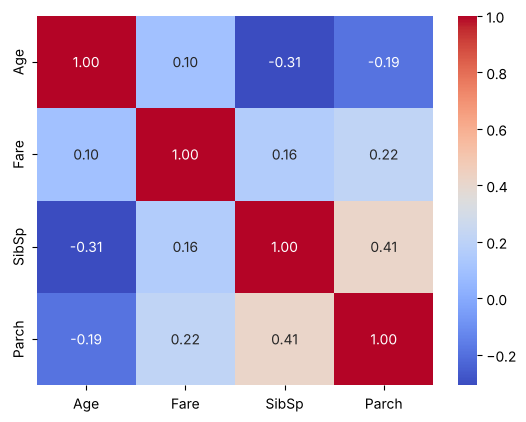

In [5]:
corr = num.corr()
print(corr)
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm")
plt.show()

## 5. Strongest correlations

In [6]:
pairs = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool)).stack()
print(pairs.sort_values(key=abs, ascending=False).head(10))

SibSp  Parch    0.414838
Age    SibSp   -0.308247
Fare   Parch    0.216225
Age    Parch   -0.189119
Fare   SibSp    0.159651
Age    Fare     0.096067
dtype: float64


## 6. Survival rate by group

Sex
female    0.742038
male      0.188908
Name: Survived, dtype: float64
Pclass
1    0.629630
2    0.472826
3    0.242363
Name: Survived, dtype: float64


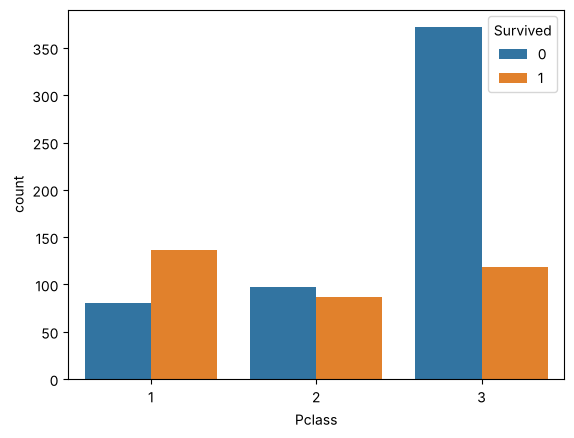

In [7]:
print(df.groupby("Sex")["Survived"].mean())
print(df.groupby("Pclass")["Survived"].mean())

sns.countplot(data=df, x="Pclass", hue="Survived")
plt.show()

## Result / Conclusion
- 891 passengers, 12 columns. Missing values: `Cabin` 687 (77%), `Age` 177 (20%), `Embarked` 2.
- 342 passengers (38.4%) survived. Survival was 74.2% for females vs 18.9% for males, and 63.0% / 47.3% / 24.2% for 1st / 2nd / 3rd class.
- `Fare` is highly right-skewed (skew 4.79, mean 32.2 vs median 14.5); `SibSp` and `Parch` are mostly 0.
- Correlations among the numeric columns are weak; the strongest is `SibSp`–`Parch` (r = 0.41), then `Age`–`SibSp` (r = −0.31).